In [1]:
import pandas as pd
from scipy.stats import skew
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE

In [2]:
kd = pd.read_csv("kidney_disease.csv")

In [3]:
kd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    int64  
 1   age             391 non-null    float64
 2   bp              388 non-null    float64
 3   sg              353 non-null    float64
 4   al              354 non-null    float64
 5   su              351 non-null    float64
 6   rbc             248 non-null    object 
 7   pc              335 non-null    object 
 8   pcc             396 non-null    object 
 9   ba              396 non-null    object 
 10  bgr             356 non-null    float64
 11  bu              381 non-null    float64
 12  sc              383 non-null    float64
 13  sod             313 non-null    float64
 14  pot             312 non-null    float64
 15  hemo            348 non-null    float64
 16  pcv             330 non-null    object 
 17  wc              295 non-null    obj

In [4]:
#DATA CLEANING STARTED

In [5]:
kd.isnull().sum()

id                  0
age                 9
bp                 12
sg                 47
al                 46
su                 49
rbc               152
pc                 65
pcc                 4
ba                  4
bgr                44
bu                 19
sc                 17
sod                87
pot                88
hemo               52
pcv                70
wc                105
rc                130
htn                 2
dm                  2
cad                 2
appet               1
pe                  1
ane                 1
classification      0
dtype: int64

In [6]:
kd.head(5)


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [7]:
kd.shape

(400, 26)

In [8]:
kd.dtypes

id                  int64
age               float64
bp                float64
sg                float64
al                float64
su                float64
rbc                object
pc                 object
pcc                object
ba                 object
bgr               float64
bu                float64
sc                float64
sod               float64
pot               float64
hemo              float64
pcv                object
wc                 object
rc                 object
htn                object
dm                 object
cad                object
appet              object
pe                 object
ane                object
classification     object
dtype: object

In [9]:
skewness = kd["age"].skew()

In [10]:
print(f"skewness:{skewness}")

skewness:-0.6682594691593559


In [11]:
kd["age"].median()

55.0

In [12]:
kd["age"].mean()

np.float64(51.48337595907928)

In [13]:
kd["sc"].head(5)

0    1.2
1    0.8
2    1.8
3    3.8
4    1.4
Name: sc, dtype: float64

In [14]:
skewed = kd["sc"].skew()

In [15]:
print(f"skewed:{skewed}")

skewed:7.509538252140634


In [16]:
kd["sc"].mean()

np.float64(3.072454308093995)

In [17]:
#normal range for serum creatinine in men= 0.74-1.35 , women= 0.59-1.04

In [18]:
kd["sc"].median()

1.3

In [19]:
kd["sc"].mode()

0    1.2
Name: sc, dtype: float64

In [20]:
kd.dropna(subset=["age"],inplace = True)

In [21]:
kd.isnull().sum()

id                  0
age                 0
bp                 12
sg                 44
al                 43
su                 46
rbc               147
pc                 61
pcc                 4
ba                  4
bgr                43
bu                 19
sc                 17
sod                84
pot                85
hemo               50
pcv                67
wc                100
rc                124
htn                 2
dm                  2
cad                 2
appet               1
pe                  1
ane                 1
classification      0
dtype: int64

In [22]:
kd = kd.dropna(subset=["ane"])

In [23]:
kd.isnull().sum()

id                  0
age                 0
bp                 12
sg                 44
al                 43
su                 46
rbc               147
pc                 61
pcc                 4
ba                  4
bgr                43
bu                 19
sc                 17
sod                84
pot                85
hemo               50
pcv                67
wc                100
rc                124
htn                 2
dm                  2
cad                 2
appet               0
pe                  0
ane                 0
classification      0
dtype: int64

In [24]:
kd["wc"] = pd.to_numeric(kd["wc"] , errors = "coerce")


In [25]:
kd.isnull().sum()

id                  0
age                 0
bp                 12
sg                 44
al                 43
su                 46
rbc               147
pc                 61
pcc                 4
ba                  4
bgr                43
bu                 19
sc                 17
sod                84
pot                85
hemo               50
pcv                67
wc                101
rc                124
htn                 2
dm                  2
cad                 2
appet               0
pe                  0
ane                 0
classification      0
dtype: int64

In [26]:
kd.notnull().sum()

id                390
age               390
bp                378
sg                346
al                347
su                344
rbc               243
pc                329
pcc               386
ba                386
bgr               347
bu                371
sc                373
sod               306
pot               305
hemo              340
pcv               323
wc                289
rc                266
htn               388
dm                388
cad               388
appet             390
pe                390
ane               390
classification    390
dtype: int64

In [27]:
kd.dtypes

id                  int64
age               float64
bp                float64
sg                float64
al                float64
su                float64
rbc                object
pc                 object
pcc                object
ba                 object
bgr               float64
bu                float64
sc                float64
sod               float64
pot               float64
hemo              float64
pcv                object
wc                float64
rc                 object
htn                object
dm                 object
cad                object
appet              object
pe                 object
ane                object
classification     object
dtype: object

In [28]:
kd.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000.0,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300.0,4.6,no,no,no,good,no,no,ckd


In [29]:
#Checking for standard strings. Turns out "dm", "cad" and "classification" are not standard strings

In [30]:
kd["classification"].unique()

array(['ckd', 'ckd\t', 'notckd'], dtype=object)

In [31]:
kd["classification"].value_counts()

classification
ckd       240
notckd    148
ckd\t       2
Name: count, dtype: int64

In [32]:
kd["dm"].value_counts()

dm
no       252
yes      131
\tno       3
\tyes      2
Name: count, dtype: int64

In [33]:
kd["cad"].value_counts()

cad
no      352
yes      34
\tno      2
Name: count, dtype: int64

In [34]:
kd["cad"] = kd["cad"]. replace({"\tno" : "no"})
kd["dm"] = kd["dm"]. replace({"\tno" : "no"})
kd["dm"] = kd["dm"]. replace({"\tyes" : "yes"})
kd["classification"] = kd["classification"].str.strip(). replace("ckd/t" , "ckd")

In [35]:
kd["classification"].value_counts()

classification
ckd       242
notckd    148
Name: count, dtype: int64

In [36]:
#Checking for duplicates and dropping them


In [37]:
kd.duplicated().sum()

np.int64(0)

In [38]:
kd.duplicated(subset=["id"]).sum()

np.int64(0)

In [39]:
kd.drop_duplicates()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000.0,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300.0,4.6,no,no,no,good,no,no,ckd
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,395,55.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,...,47,6700.0,4.9,no,no,no,good,no,no,notckd
396,396,42.0,70.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,54,7800.0,6.2,no,no,no,good,no,no,notckd
397,397,12.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,...,49,6600.0,5.4,no,no,no,good,no,no,notckd
398,398,17.0,60.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,51,7200.0,5.9,no,no,no,good,no,no,notckd


In [40]:
kd.drop(columns=['hemo','pcv','rc'], inplace=True)

In [41]:
kd.head(5)

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,sod,pot,wc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,NaN,NaN,7800.0,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,NaN,NaN,6000.0,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,NaN,NaN,7500.0,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,111.0,2.5,6700.0,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,NaN,NaN,7300.0,no,no,no,good,no,no,ckd


In [42]:
kd.dtypes

id                  int64
age               float64
bp                float64
sg                float64
al                float64
su                float64
rbc                object
pc                 object
pcc                object
ba                 object
bgr               float64
bu                float64
sc                float64
sod               float64
pot               float64
wc                float64
htn                object
dm                 object
cad                object
appet              object
pe                 object
ane                object
classification     object
dtype: object

In [43]:
#DATA CLEANING JUST ENDED


In [44]:
#GATHERING INSIGHTS FROM DATA AND DATA VISUALIZATION

In [45]:
#1. What is the age range of those diagnosed with CKD? 

In [46]:
print(kd['age'].unique())

[48.  7. 62. 51. 60. 68. 24. 52. 53. 50. 63. 40. 47. 61. 21. 42. 75. 69.
 73. 70. 65. 76. 72. 82. 46. 45. 35. 54. 11. 59. 67. 15. 55. 44. 26. 64.
 56.  5. 74. 38. 58. 71. 34. 17. 12. 43. 41. 57.  8. 39. 66. 81. 14. 27.
 83. 30.  4.  3.  6. 32. 80. 49. 90. 78. 19.  2. 33. 36. 37. 23. 25. 20.
 29. 28. 22. 79.]


In [47]:
def new_column(age):
    if age < 10:
        return "0-9"
    elif age < 20:
        return "10-19"
    elif age < 30:
        return "20-29"
    elif age < 40:
        return "30-39"
    elif age < 50:
        return "40-49"
    elif age < 60:
        return "50-59"
    elif age < 70:
        return "60-69"
    elif age >= 70:
        return "70+"
    else:
        return "Missing"
   

In [48]:
kd["age_groups"] = kd["age"]. apply(new_column)

In [49]:
print (kd["age_groups"])

0      40-49
1        0-9
2      60-69
3      40-49
4      50-59
       ...  
395    50-59
396    40-49
397    10-19
398    10-19
399    50-59
Name: age_groups, Length: 390, dtype: object


In [50]:
kd.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pot,wc,htn,dm,cad,appet,pe,ane,classification,age_groups
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,NaN,7800.0,yes,yes,no,good,no,no,ckd,40-49
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,NaN,6000.0,no,no,no,good,no,no,ckd,0-9
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,NaN,7500.0,no,yes,no,poor,no,yes,ckd,60-69
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,2.5,6700.0,yes,no,no,poor,yes,yes,ckd,40-49
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,NaN,7300.0,no,no,no,good,no,no,ckd,50-59


In [51]:
ckd_only = kd[kd["classification"] == "ckd"]

In [52]:
print(ckd_only)

      id   age     bp     sg   al   su       rbc        pc         pcc  \
0      0  48.0   80.0  1.020  1.0  0.0       NaN    normal  notpresent   
1      1   7.0   50.0  1.020  4.0  0.0       NaN    normal  notpresent   
2      2  62.0   80.0  1.010  2.0  3.0    normal    normal  notpresent   
3      3  48.0   70.0  1.005  4.0  0.0    normal  abnormal     present   
4      4  51.0   80.0  1.010  2.0  0.0    normal    normal  notpresent   
..   ...   ...    ...    ...  ...  ...       ...       ...         ...   
245  245  48.0  100.0    NaN  NaN  NaN       NaN       NaN  notpresent   
246  246  48.0  110.0  1.015  3.0  0.0  abnormal    normal     present   
247  247  54.0   90.0  1.025  1.0  0.0    normal  abnormal  notpresent   
248  248  59.0   70.0  1.010  1.0  3.0  abnormal  abnormal  notpresent   
249  249  56.0   90.0  1.010  4.0  1.0    normal  abnormal     present   

             ba  ...  pot       wc  htn   dm  cad  appet   pe  ane  \
0    notpresent  ...  NaN   7800.0  yes  

In [53]:
plt.figure(figsize=(12,6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

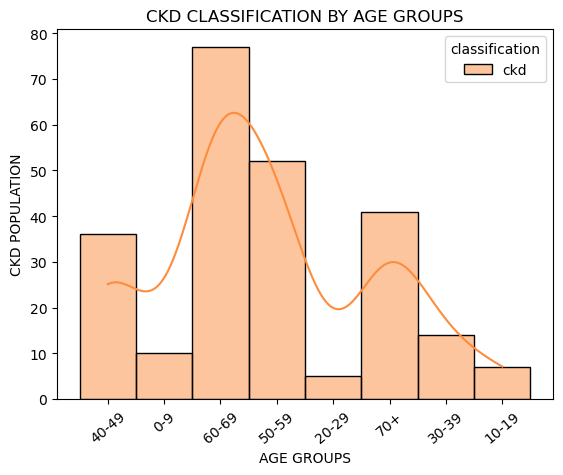

In [54]:
sns.histplot (data = ckd_only , x = "age_groups", bins = 12, kde = True,hue = "classification", palette = "YlOrRd")
plt.title("CKD CLASSIFICATION BY AGE GROUPS")
plt.xlabel("AGE GROUPS")
plt.ylabel("CKD POPULATION")
plt.xticks(rotation = 40)

plt.show()

In [55]:
#From the histogram plotted, we can deduce that all age ranges have a CKD patient but there is variation in the population of CKD patients belonging to each age groups. 

In [56]:
#2. Among CKD patients, which pairs of measurements move together most strongly?

In [57]:
kd.info()

<class 'pandas.core.frame.DataFrame'>
Index: 390 entries, 0 to 399
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              390 non-null    int64  
 1   age             390 non-null    float64
 2   bp              378 non-null    float64
 3   sg              346 non-null    float64
 4   al              347 non-null    float64
 5   su              344 non-null    float64
 6   rbc             243 non-null    object 
 7   pc              329 non-null    object 
 8   pcc             386 non-null    object 
 9   ba              386 non-null    object 
 10  bgr             347 non-null    float64
 11  bu              371 non-null    float64
 12  sc              373 non-null    float64
 13  sod             306 non-null    float64
 14  pot             305 non-null    float64
 15  wc              289 non-null    float64
 16  htn             388 non-null    object 
 17  dm              388 non-null    object 


In [58]:
cols = ["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot", "wc"]
ckd_num = kd[kd["classification"] == "ckd"][cols]

#Before answering this question, let's give a range to the various parameters we are looking at :
1. Blood pressure : < 120/80mmHg
2. Specific gravity : 1.005 to 1.030
3.  Albumin (Urine or Blood):
In Blood (Serum): 3.5 to 5.0 g/dL
In Urine: Less than 30 mg/g
4.  Sugar (Urine Glucose): Negative (or 0 to 15 mg/dL)
5.  Random Blood Glucose: Between 70 and 140 mg/dL
6.  Blood Urea (BUN): 7 to 20 mg/dL (2.5 to 7.1 mmol/L).
7. Serum Creatinine:Adult Males: 0.7 to 1.3 mg/dL (61.9 to 114.9 µmol/L)
Adult Females: 0.6 to 1.1 mg/dL (53.0 to 97.2 µmol/L)
8. Sodium ($Na^+$): 135 to 145 mEq/L (or mmol/L)
9. Potassium ($K^+$): 3.5 to 5.0 mEq/L (or mmol/L)
10. Hemoglobin (Hb):
Adult Males: 13.8 to 17.2 g/dL
Adult Females: 12.1 to 15.1 g/dL
11. Packed Cell Volume (PCV / Hematocrit):
Adult Males: 41% to 50%
Adult Females: 36% to 48%
12. White Blood Cell Count (WBC): 4,500 to 11,000 cells/µL 
13. Red Blood Cell Count (RBC):
Adult Males: 4.7 to 6.1 million cells/µL
Adult Females: 4.2 to 5.4 million cells/µL

This question will require for me to do the plotting of each parameter with ckd. That's a lot. I will get back to it when i have time. 


In [59]:
corr = ckd_num.corr(method="spearman")

In [60]:
mask = np.triu(np.ones_like(corr, dtype=bool))

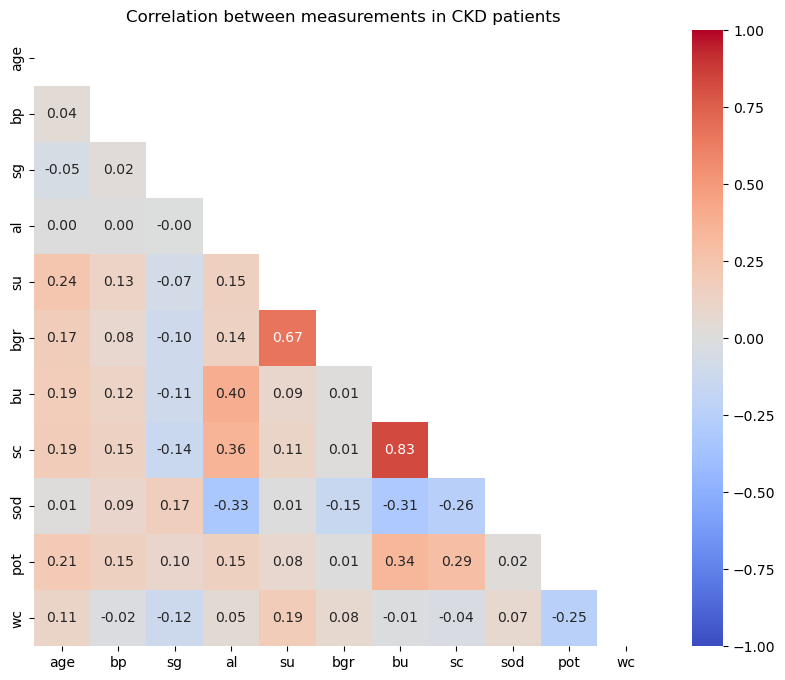

In [61]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation between measurements in CKD patients")
plt.show()

In [62]:
pairs = corr.where(~mask).stack().sort_values(key=abs, ascending=False)
print(pairs.head(5))

sc   bu    0.834263
bgr  su    0.671402
bu   al    0.396459
sc   al    0.358370
pot  bu    0.339197
dtype: float64


In [63]:
#3. Do serum creatinine and blood urea rise together, and does the pattern differ between age groups?

In [64]:
 kd[kd['sod'] < 20]

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pot,wc,htn,dm,cad,appet,pe,ane,classification,age_groups
21,21,60.0,90.0,NaN,NaN,NaN,NaN,NaN,notpresent,notpresent,...,NaN,6200.0,yes,yes,yes,good,no,no,ckd,60-69


In [65]:
# Sodium below 20 is impossible for a living human
# Remove impossible sodium values. Keep blanks.
kd = kd[(kd["sod"] >= 20) | (kd["sod"].isna())]

In [66]:
kd['age_group'] = pd.cut(
    kd['age'],
    bins=[0, 18, 35, 50, 65, 100],
    labels=['0-18', '19-35', '36-50', '51-65', '65+']
)

In [67]:
plot_df = kd[kd["age_group"]!= "65+"].copy()

In [68]:
kd['sc_capped'] = kd['sc'].clip(lower=0, upper=40) 

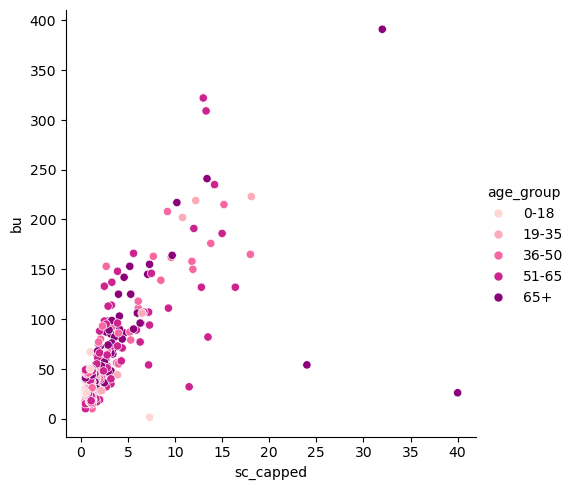

In [69]:
sns.relplot(data=kd, x="sc_capped", y="bu", hue="age_group", palette="RdPu")
plt.show()


In [70]:
#4. How is age distributed among patients with normal vs abnormal pus cells, and does the presence of pus cell clumps (pcc) change that pattern?

In [71]:
plt.figure(figsize=(12,8))

<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

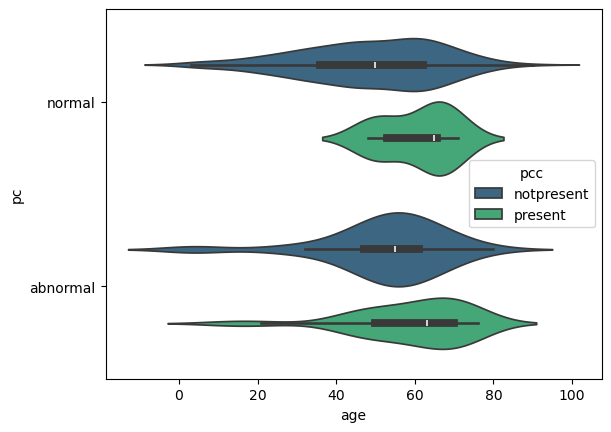

In [72]:
sns.violinplot(data=kd, x="age",y="pc", hue="pcc", palette="viridis")
plt.show()

In [73]:
#5. Compare the sodium levels of the patients with their blood pressure

In [74]:
x="sod"
y="bp"
sizes="age"

<Axes: xlabel='sod', ylabel='bp'>

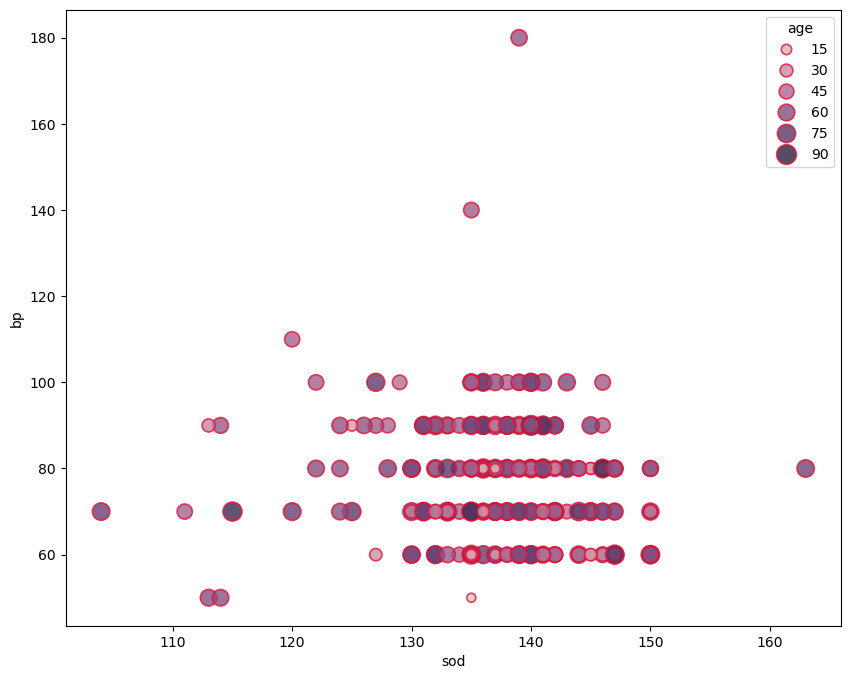

In [75]:
fig, ax = plt.subplots(figsize=(10,8))
sns.scatterplot(data=kd,
                x="sod",
                y="bp",
                size="age", 
                hue="age",
                sizes=(30,200),
                alpha=0.8,
                edgecolor="crimson",
                linewidth=1.2,)
                

In [76]:
#7. From the data given, will you say people with ckd are more prone to coronary artery disease than hypertension?

In [77]:
ckd_only["cad"].sort_values().mode(0)

0    no
Name: cad, dtype: object

In [78]:
ckd_only["htn"].sort_values().mode(0)

0    yes
Name: htn, dtype: object

In [79]:
#8. As urine specific gravity rises, how does average urine albumin change, and does the pattern differ between CKD and non-CKD patients?

In [80]:
plt.figure(figsize=(14,5))

<Figure size 1400x500 with 0 Axes>

<Figure size 1400x500 with 0 Axes>

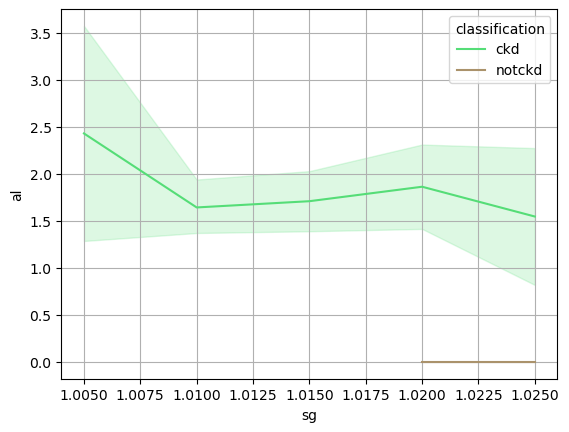

In [81]:
sns.lineplot(data=kd, x="sg", y="al",hue="classification",palette="terrain")
plt.grid(True)
plt.show()

In [82]:
#9. How many non ckd patients have diabetes mellitus?


In [83]:
notckd_only = kd[kd["classification"] == "notckd"]

In [84]:
notckd_only.head(5)

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,htn,dm,cad,appet,pe,ane,classification,age_groups,age_group,sc_capped
250,250,40.0,80.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,no,no,no,good,no,no,notckd,40-49,36-50,1.2
251,251,23.0,80.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,no,no,no,good,no,no,notckd,20-29,19-35,1.0
252,252,45.0,80.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,no,no,no,good,no,no,notckd,40-49,36-50,0.6
253,253,57.0,80.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,no,no,no,good,no,no,notckd,50-59,51-65,1.2
254,254,51.0,60.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,no,no,no,good,no,no,notckd,50-59,51-65,0.8


In [85]:
kd["classification"].value_counts()

classification
ckd       241
notckd    148
Name: count, dtype: int64

In [86]:
notckd_only["dm"].value_counts()

dm
no    146
Name: count, dtype: int64

In [87]:
#everyone that didn't have ckd didn't have diabetes mellitus

In [88]:
#10. For ckd patients of different age ranges, what comorbidities seem to be most pronounced?

In [89]:
ckd_only.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pot,wc,htn,dm,cad,appet,pe,ane,classification,age_groups
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,NaN,7800.0,yes,yes,no,good,no,no,ckd,40-49
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,NaN,6000.0,no,no,no,good,no,no,ckd,0-9
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,NaN,7500.0,no,yes,no,poor,no,yes,ckd,60-69
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,2.5,6700.0,yes,no,no,poor,yes,yes,ckd,40-49
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,NaN,7300.0,no,no,no,good,no,no,ckd,50-59


In [90]:
ckd_only.groupby("age_groups")["bp"].mean()

age_groups
0-9      54.000000
10-19    66.666667
20-29    72.500000
30-39    77.857143
40-49    81.944444
50-59    85.882353
60-69    78.157895
70+      79.750000
Name: bp, dtype: float64

In [91]:
ckd_only.groupby("age_groups")["htn"].value_counts()

age_groups  htn
0-9         no     10
10-19       no      6
            yes     1
20-29       no      5
30-39       no     10
            yes     4
40-49       yes    19
            no     17
50-59       yes    32
            no     20
60-69       yes    56
            no     21
70+         yes    30
            no     11
Name: count, dtype: int64

In [92]:
ckd_only.groupby("age_groups")["dm"].value_counts()

age_groups  dm 
0-9         no     10
10-19       no      5
            yes     2
20-29       no      3
            yes     2
30-39       no     11
            yes     3
40-49       no     23
            yes    13
50-59       yes    35
            no     17
60-69       yes    47
            no     30
70+         yes    31
            no     10
Name: count, dtype: int64

In [93]:
kd.groupby("age_groups")["dm"].value_counts()

age_groups  dm 
0-9         no     10
10-19       no      9
            yes     2
20-29       no     21
            yes     2
30-39       no     40
            yes     3
40-49       no     58
            yes    13
50-59       no     45
            yes    35
60-69       no     49
            yes    46
70+         yes    31
            no     23
Name: count, dtype: int64

In [94]:
ckd_only.groupby("age_groups")["cad"].value_counts()

age_groups  cad
0-9         no     10
10-19       no      7
20-29       no      5
30-39       no     14
40-49       no     33
            yes     3
50-59       no     48
            yes     4
60-69       no     59
            yes    18
70+         no     32
            yes     9
Name: count, dtype: int64

In [95]:
#FEATURE ENGINEERING

In [96]:
kd.head(5)

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,htn,dm,cad,appet,pe,ane,classification,age_groups,age_group,sc_capped
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,yes,yes,no,good,no,no,ckd,40-49,36-50,1.2
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,no,no,no,good,no,no,ckd,0-9,0-18,0.8
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,no,yes,no,poor,no,yes,ckd,60-69,51-65,1.8
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,yes,no,no,poor,yes,yes,ckd,40-49,36-50,3.8
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,no,no,no,good,no,no,ckd,50-59,51-65,1.4


In [97]:
#PREDICTIVE MODELS TO DO

In [98]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [99]:
kd_model = kd[kd["classification"] == "ckd"].copy()


In [100]:
print(pd.crosstab(kd["classification"], kd["ane"]))

ane              no  yes
classification          
ckd             184   57
notckd          148    0


In [101]:
kd_model["ane"] = kd_model["ane"].replace({"yes": 1, "no": 0})

C:\Users\HP\AppData\Local\Temp\ipykernel_19884\1858958752.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  kd_model["ane"] = kd_model["ane"].replace({"yes": 1, "no": 0})


In [102]:
X = kd_model[["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot", "wc"]]
y = kd_model["ane"]

In [103]:
print(y.value_counts())

ane
0    184
1     57
Name: count, dtype: int64


In [104]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, cross_validate
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
scoring = {"recall": "recall", "precision": "precision",
           "f1": "f1", "roc_auc": "roc_auc"}

In [105]:
spw = (y == 0).sum() / (y == 1).sum()

In [106]:
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=5000),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", random_state=42),
}

In [107]:
rows = []

In [108]:
for name, model in models.items():
    pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
        ("model", model),
    ])
    results = cross_validate(pipe, X, y, cv=cv, scoring=scoring)

    row = {"model": name}
    for metric in scoring:
        s = results[f"test_{metric}"]
        row[metric] = f"{s.mean():.2f} ± {s.std():.2f}"
    rows.append(row)


In [109]:
print(rows)

[{'model': 'Logistic Regression', 'recall': '0.54 ± 0.13', 'precision': '0.35 ± 0.08', 'f1': '0.42 ± 0.09', 'roc_auc': '0.65 ± 0.08'}, {'model': 'Random Forest', 'recall': '0.27 ± 0.13', 'precision': '0.66 ± 0.25', 'f1': '0.37 ± 0.16', 'roc_auc': '0.68 ± 0.07'}, {'model': 'XGBoost', 'recall': '0.39 ± 0.13', 'precision': '0.45 ± 0.12', 'f1': '0.41 ± 0.11', 'roc_auc': '0.66 ± 0.07'}]


In [110]:
summary = pd.DataFrame(rows).set_index("model")


In [111]:
print(summary)

                          recall    precision           f1      roc_auc
model                                                                  
Logistic Regression  0.54 ± 0.13  0.35 ± 0.08  0.42 ± 0.09  0.65 ± 0.08
Random Forest        0.27 ± 0.13  0.66 ± 0.25  0.37 ± 0.16  0.68 ± 0.07
XGBoost              0.39 ± 0.13  0.45 ± 0.12  0.41 ± 0.11  0.66 ± 0.07


In [112]:
summary_1 = summary.copy()

In [113]:
add_cols = ["htn", "dm", "cad", "appet", "pe"]


In [114]:
for col in add_cols:
    print(col, kd_model[col].unique())

htn ['yes' 'no']
dm ['yes' 'no']
cad ['no' 'yes']
appet ['good' 'poor']
pe ['no' 'yes']


In [115]:
binary_map = {"yes": 1, "no": 0, "poor": 1, "good": 0}

In [116]:
for col in add_cols:
    kd_model[col] = kd_model[col].str.strip().map(binary_map)

In [117]:
num_cols = ["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot", "wc"]



In [118]:
X = kd_model[num_cols + add_cols]
y = kd_model["ane"]

In [119]:
spw = (y == 0).sum() / (y == 1).sum()

In [120]:
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=5000),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", random_state=42),
}

In [121]:
rows = []

In [122]:
for name, model in models.items():
    pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
        ("model", model),
    ])
    results = cross_validate(pipe, X, y, cv=cv, scoring=scoring)

    row = {"model": name}
    for metric in scoring:
        s = results[f"test_{metric}"]
        row[metric] = f"{s.mean():.2f} ± {s.std():.2f}"
    rows.append(row)

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [123]:
print(rows)

[{'model': 'Logistic Regression', 'recall': '0.55 ± 0.13', 'precision': '0.36 ± 0.07', 'f1': '0.43 ± 0.08', 'roc_auc': '0.64 ± 0.10'}, {'model': 'Random Forest', 'recall': '0.27 ± 0.12', 'precision': '0.75 ± 0.29', 'f1': '0.39 ± 0.15', 'roc_auc': '0.70 ± 0.08'}, {'model': 'XGBoost', 'recall': '0.40 ± 0.13', 'precision': '0.50 ± 0.15', 'f1': '0.44 ± 0.12', 'roc_auc': '0.66 ± 0.07'}]


In [124]:
summary = pd.DataFrame(rows).set_index("model")


In [125]:
print(summary)

                          recall    precision           f1      roc_auc
model                                                                  
Logistic Regression  0.55 ± 0.13  0.36 ± 0.07  0.43 ± 0.08  0.64 ± 0.10
Random Forest        0.27 ± 0.12  0.75 ± 0.29  0.39 ± 0.15  0.70 ± 0.08
XGBoost              0.40 ± 0.13  0.50 ± 0.15  0.44 ± 0.12  0.66 ± 0.07


In [126]:
print(X.shape)
print(X.isna().sum())

(241, 16)
age       0
bp       10
sg       39
al       38
su       41
bgr      36
bu       13
sc       12
sod      79
pot      79
wc       94
htn       0
dm        0
cad       0
appet     0
pe        0
dtype: int64


In [127]:
print(summary_1)
print(summary)

                          recall    precision           f1      roc_auc
model                                                                  
Logistic Regression  0.54 ± 0.13  0.35 ± 0.08  0.42 ± 0.09  0.65 ± 0.08
Random Forest        0.27 ± 0.13  0.66 ± 0.25  0.37 ± 0.16  0.68 ± 0.07
XGBoost              0.39 ± 0.13  0.45 ± 0.12  0.41 ± 0.11  0.66 ± 0.07
                          recall    precision           f1      roc_auc
model                                                                  
Logistic Regression  0.55 ± 0.13  0.36 ± 0.07  0.43 ± 0.08  0.64 ± 0.10
Random Forest        0.27 ± 0.12  0.75 ± 0.29  0.39 ± 0.15  0.70 ± 0.08
XGBoost              0.40 ± 0.13  0.50 ± 0.15  0.44 ± 0.12  0.66 ± 0.07


In [128]:
def split_mean_sd(df):
    mean = df.apply(lambda col: col.str.split(" ± ").str[0].astype(float))
    sd   = df.apply(lambda col: col.str.split(" ± ").str[1].astype(float))
    return mean, sd

In [129]:
before_mean, before_sd = split_mean_sd(summary_1)
after_mean,  after_sd  = split_mean_sd(summary)

In [130]:
metrics = {"recall": "Recall (anemic patients caught)",
           "precision": "Precision (flags that are correct)",
           "f1": "F1 (balance of the two)",
           "roc_auc": "ROC AUC (ranking skill)"}
models_list = list(before_mean.index)
x = np.arange(len(models_list))
w = 0.36

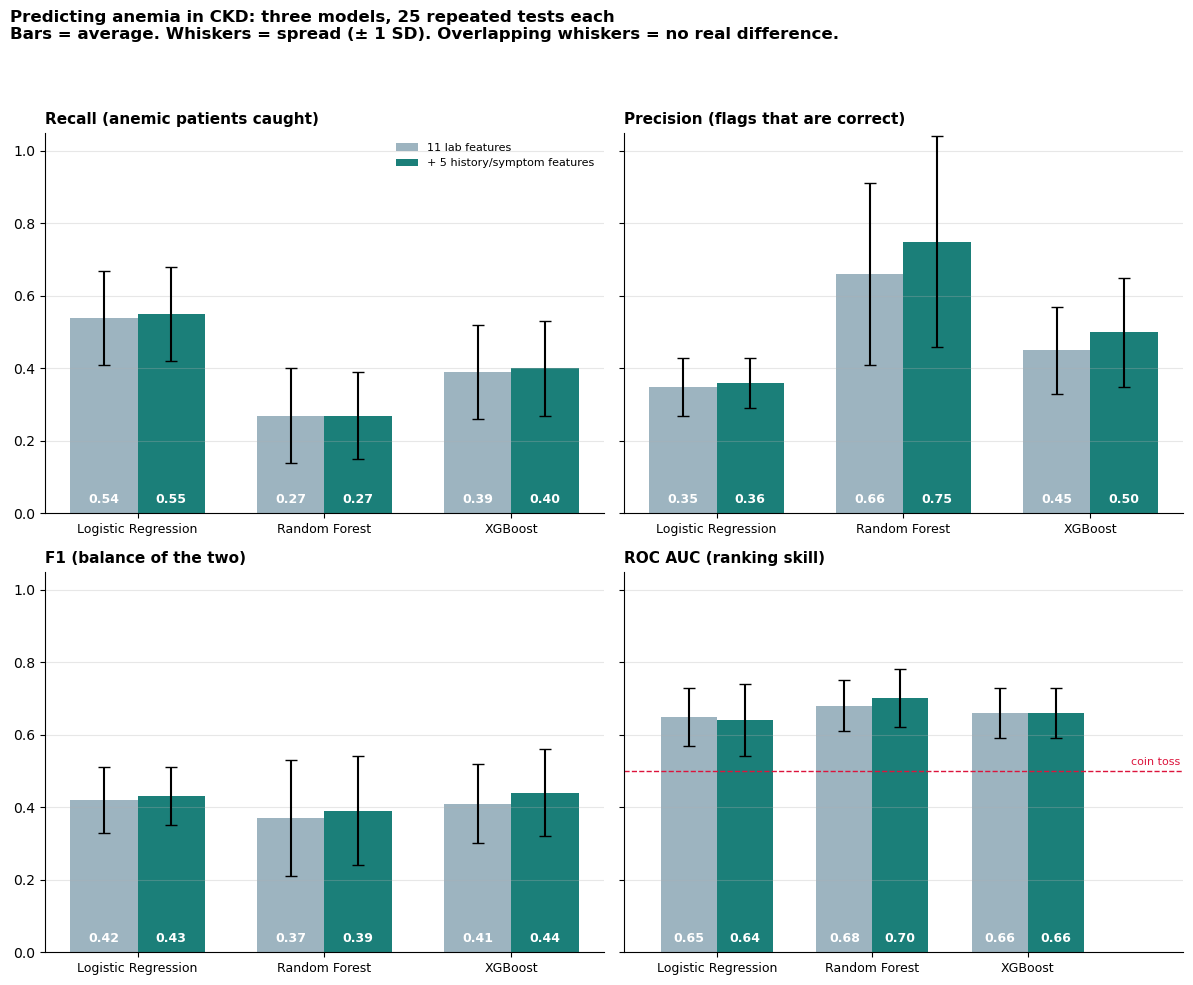

In [131]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharey=True)
for ax, (m, title) in zip(axes.flat, metrics.items()):
    b = ax.bar(x - w/2, before_mean[m], w, yerr=before_sd[m], capsize=4,
           color="#9DB4C0", label="11 lab features")
    a = ax.bar(x + w/2, after_mean[m],  w, yerr=after_sd[m],  capsize=4,
           color="#1B7F79", label="+ 5 history/symptom features")
    for bars in (b, a):
        for bar in bars:
            ax.text(bar.get_x() + bar.get_width()/2, 0.02, f"{bar.get_height():.2f}",
                    ha="center", va="bottom", fontsize=9, color="white", fontweight="bold")
            ax.set_title(title, fontsize=11, fontweight="bold", loc="left")
    ax.set_xticks(x)
    ax.set_xticklabels(models_list, fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    if m == "roc_auc":
        ax.axhline(0.5, color="crimson", linestyle="--", linewidth=1)
        ax.set_xlim(-0.6, 3.0)
        ax.text(2.98, 0.51, "coin toss", color="crimson", fontsize=8, ha="right", va="bottom")
axes[0, 0].legend(loc="upper right", fontsize=8, frameon=False)
fig.suptitle("Predicting anemia in CKD: three models, 25 repeated tests each\n"
             "Bars = average. Whiskers = spread (± 1 SD). Overlapping whiskers = no real difference.",
             fontsize=12, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
           